# Evaluation under obs noise

## Setup

In [1]:
import gymnasium
import highway_env
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from stable_baselines3 import DQN

model = DQN.load("artifacts/model.zip")
env = gymnasium.make("highway-fast-v0")

sigmas = np.concatenate([
    np.linspace(0.0, 0.01, 11),
    np.linspace(0.012, 0.03, 10),
    np.linspace(0.035, 0.06, 6),
    np.array([0.075, 0.09, 0.12, 0.15])
]).round(4).tolist()

rng = np.random.RandomState(1234)
N_EPISODES = 100

print(f"Evaluating {len(sigmas)} sigma values × {N_EPISODES} episodes = {len(sigmas)*N_EPISODES} episodes")
sigmas

objc[50868]: Class SDL_RumbleMotor is implemented in both /opt/homebrew/Cellar/sdl2/2.32.10/lib/libSDL2-2.0.0.dylib (0x10ebc4138) and /Users/frederikbach/models/.venv/lib/python3.14/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x10f0c49c8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[50868]: Class SDL_RumbleContext is implemented in both /opt/homebrew/Cellar/sdl2/2.32.10/lib/libSDL2-2.0.0.dylib (0x10ebc4188) and /Users/frederikbach/models/.venv/lib/python3.14/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x10f0c4a18). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[50868]: Class SDLApplication is implemented in both /opt/homebrew/Cellar/sdl2/2.32.10/lib/libSDL2-2.0.0.dylib (0x10ebc3c88) and /Users/frederikbach/models/.venv/lib/python3.14/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x10f0c4a68). This may cause spurious casting

Evaluating 31 sigma values × 100 episodes = 3100 episodes


[0.0,
 0.001,
 0.002,
 0.003,
 0.004,
 0.005,
 0.006,
 0.007,
 0.008,
 0.009,
 0.01,
 0.012,
 0.014,
 0.016,
 0.018,
 0.02,
 0.022,
 0.024,
 0.026,
 0.028,
 0.03,
 0.035,
 0.04,
 0.045,
 0.05,
 0.055,
 0.06,
 0.075,
 0.09,
 0.12,
 0.15]

## Run evaluation

In [2]:
results = []
for sigma in sigmas:
    rets, lens, crashes = [], [], []
    for episode in range(N_EPISODES):
        obs, info = env.reset(seed=episode)
        done = truncated = False
        ep_ret = 0.0
        steps = 0
        crashed = False
        while not (done or truncated):
            if sigma > 0:
                obs_noisy = obs + rng.randn(*obs.shape) * sigma
            else:
                obs_noisy = obs
            action, _ = model.predict(obs_noisy, deterministic=True)
            obs, reward, done, truncated, info = env.step(action)
            ep_ret += reward
            steps += 1
            crashed = crashed or info.get("crashed", False)
        rets.append(ep_ret)
        lens.append(steps)
        crashes.append(crashed)
    results.append({
        "sigma": float(sigma),
        "mean_return": float(np.mean(rets)),
        "mean_length": float(np.mean(lens)),
        "crash_rate": float(np.mean(crashes)),
    })
    print(f"sigma={sigma:.4f}: ret={np.mean(rets):.2f} len={np.mean(lens):.2f} crash={np.mean(crashes):.0%}")

env.close()
df = pd.DataFrame(results)
df

sigma=0.0000: ret=19.72 len=24.68 crash=32%


sigma=0.0010: ret=19.72 len=24.72 crash=33%


sigma=0.0020: ret=20.11 len=25.19 crash=32%


sigma=0.0030: ret=20.46 len=25.57 crash=28%


sigma=0.0040: ret=20.25 len=25.36 crash=29%


sigma=0.0050: ret=20.22 len=25.27 crash=29%


... (22 outputs left out)

sigma=0.0900: ret=11.51 len=14.52 crash=82%


sigma=0.1200: ret=12.30 len=15.88 crash=82%


sigma=0.1500: ret=9.46 len=12.55 crash=90%


,sigma,mean_return,mean_length,crash_rate
0,0.000,19.720233,24.68,0.32
1,0.001,19.722682,24.72,0.33
2,0.002,20.108737,25.19,0.32
3,0.003,20.457444,25.57,0.28
4,0.004,20.248680,25.36,0.29
5,0.005,20.220282,25.27,0.29
6,0.006,19.480924,24.41,0.36
7,0.007,19.992724,25.10,0.30
8,0.008,20.088151,25.07,0.32
9,0.009,19.289609,23.99,0.35


## Plots

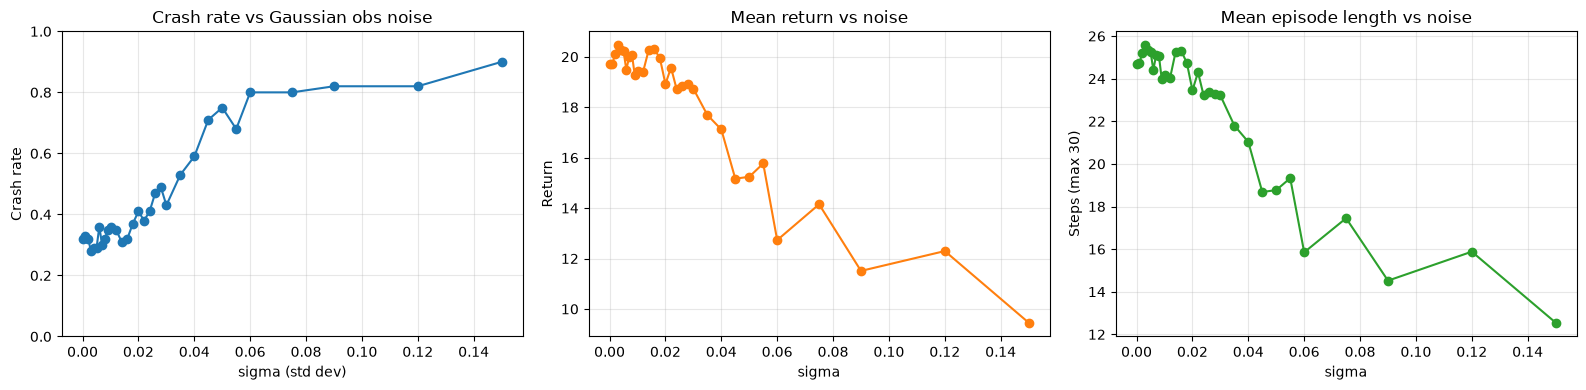

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(df["sigma"], df["crash_rate"], marker='o')
axes[0].set_title("Crash rate vs Gaussian obs noise")
axes[0].set_xlabel("sigma (std dev)")
axes[0].set_ylabel("Crash rate")
axes[0].set_ylim(0, 1)
axes[0].grid(alpha=0.3)

axes[1].plot(df["sigma"], df["mean_return"], marker='o', color='C1')
axes[1].set_title("Mean return vs noise")
axes[1].set_xlabel("sigma")
axes[1].set_ylabel("Return")
axes[1].grid(alpha=0.3)

axes[2].plot(df["sigma"], df["mean_length"], marker='o', color='C2')
axes[2].set_title("Mean episode length vs noise")
axes[2].set_xlabel("sigma")
axes[2].set_ylabel("Steps (max 30)")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()